In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from scipy import stats
import diptest

import sys
import os

# Allow notebook to import our custom library from src/
sys.path.append(os.path.abspath("../src"))

from quantlib import *

In [2]:
INDICES = {
    "DJIA": "^DJI",
    "NASDAQ": "^IXIC",
    "NIKKEI": "^N225",
    "IPC": "^MXX"
}

INDICES

{'DJIA': '^DJI', 'NASDAQ': '^IXIC', 'NIKKEI': '^N225', 'IPC': '^MXX'}

In [3]:
START_DATE = "2015-01-01"
END_DATE = "2026-06-01"

DATA_DIR = "../data"

os.makedirs(DATA_DIR, exist_ok=True)

market_data = {}

for name, ticker in INDICES.items():

    print(f"Downloading {name} ({ticker})...")

    df = yf.download(
        ticker,
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False
    )

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df.dropna()

    # Save raw data
    file_path = os.path.join(
        DATA_DIR,
        f"{name}.csv"
    )

    df.to_csv(file_path)
    # Keep a copy in memory for analysis
    market_data[name] = df

    print(
        f"{name}: {len(df)} rows saved to {file_path}"
    )

DJIA: 2868 rows saved to ../data\DJIA.csv
NASDAQ: 2868 rows saved to ../data\NASDAQ.csv
NIKKEI: 2785 rows saved to ../data\NIKKEI.csv
IPC: 2867 rows saved to ../data\IPC.csv


In [4]:
processed_data = {}

for name, df in market_data.items():
    processed_data[name] = prepare_indicators(df)
    print(
        f"{name}: "
        f"{len(processed_data[name])} rows"
    )

DJIA: 2868 rows
NASDAQ: 2868 rows
NIKKEI: 2785 rows
IPC: 2867 rows


In [5]:
processed_data["DJIA"].head()
processed_data["DJIA"].columns

Index(['Close', 'High', 'Low', 'Open', 'Volume', 'Return', 'RSI', 'MACD',
       'MACD_Signal', 'MACD_Hist', 'DMA20', 'DMA50', 'ADX'],
      dtype='str', name='Price')

In [6]:
for name, df in processed_data.items():

    file_path = (
        f"../data/processed/"
        f"{name}_processed.csv"
    )

    df.to_csv(file_path)

    print(f"Saved: {file_path}")

Saved: ../data/processed/DJIA_processed.csv
Saved: ../data/processed/NASDAQ_processed.csv
Saved: ../data/processed/NIKKEI_processed.csv
Saved: ../data/processed/IPC_processed.csv


In [7]:
djia = processed_data["DJIA"].copy()
rsi_signal = rsi_strategy(djia)
rsi_backtest = backtest_strategy(
    djia,
    rsi_signal
)

rsi_backtest[
    [
        "Close",
        "RSI",
        "Position",
        "Return",
        "Strategy_Return"
    ]
].tail(20)

Price,Close,RSI,Position,Return,Strategy_Return
Date,,,,,
2026-05-01,49499.269531,62.751794,1.0,-0.003079,-0.003079
2026-05-04,48941.898438,54.997555,1.0,-0.011260,-0.011260
2026-05-05,49298.250000,58.526183,1.0,0.007281,0.007281
2026-05-06,49910.589844,63.781499,1.0,0.012421,0.012421
2026-05-07,49596.968750,59.614942,1.0,-0.006284,-0.006284
2026-05-08,49609.160156,59.725083,1.0,0.000246,0.000246
2026-05-11,49704.468750,60.629083,1.0,0.001921,0.001921
2026-05-12,49760.558594,61.181302,1.0,0.001128,0.001128
2026-05-13,49693.199219,60.091254,1.0,-0.001354,-0.001354


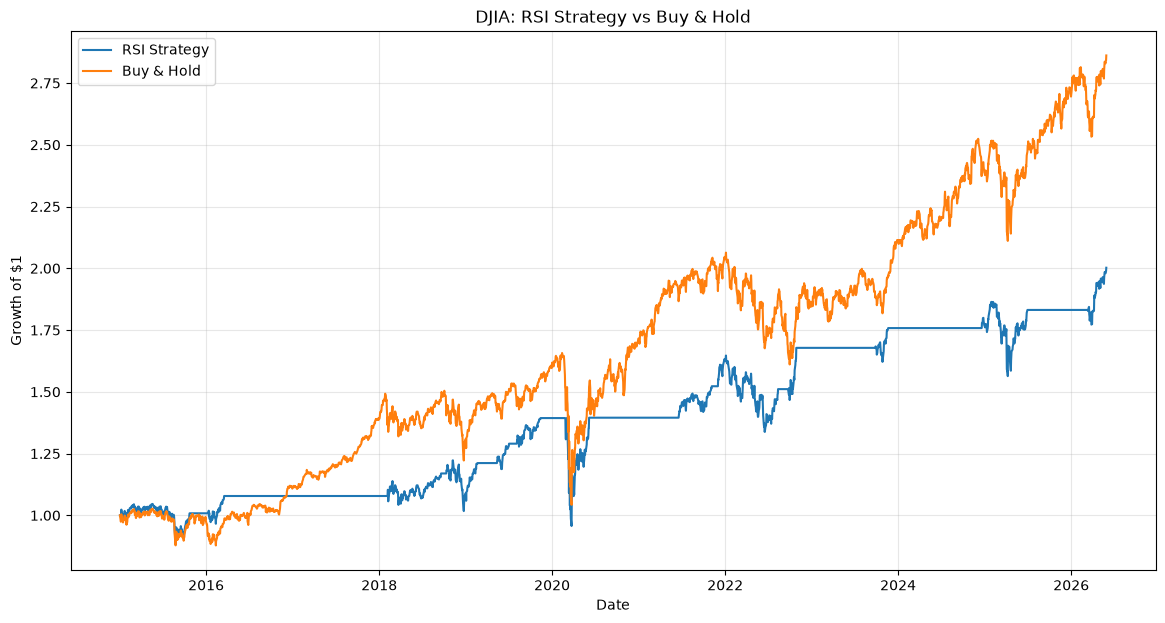

In [8]:
plt.figure(figsize=(14, 7))
plt.plot(
    rsi_backtest.index,
    rsi_backtest["Strategy_Equity"],
    label="RSI Strategy"
)
plt.plot(
    rsi_backtest.index,
    rsi_backtest["Benchmark_Equity"],
    label="Buy & Hold"
)
plt.title(
    "DJIA: RSI Strategy vs Buy & Hold"
)

plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [9]:
rsi_metrics = performance_metrics(
    rsi_backtest["Strategy_Return"]
)
rsi_metrics

{'Total Return': np.float64(1.00234165875586),
 'Annualized Return': np.float64(0.06292893155595336),
 'Annualized Volatility': np.float64(0.14405014767522065),
 'Sharpe Ratio': np.float64(0.4959718804933579),
 'Maximum Drawdown': np.float64(-0.3137194568047919),
 'Win Rate': np.float64(0.22392745029647715)}

In [10]:
strategies = {
    "RSI": rsi_strategy,
    "MACD": macd_strategy,
    "DMA": dma_strategy,
    "ADX": adx_strategy
}

djia_results = {}
for strategy_name, strategy_function in strategies.items():

    signal = strategy_function(djia)

    backtest = backtest_strategy(
        djia,
        signal
    )
    metrics = performance_metrics(
        backtest["Strategy_Return"]
    )
    djia_results[strategy_name] = {
        "backtest": backtest,
        "metrics": metrics
    }

    djia_results.keys()
    

In [11]:
djia_comparison = pd.DataFrame({
    strategy: result["metrics"]
    for strategy, result
    in djia_results.items()
}).T

djia_comparison

,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Win Rate
RSI,1.002342,0.062929,0.144050,0.495972,-0.313719,0.223927
MACD,0.970283,0.061422,0.098132,0.656556,-0.150110,0.273805
DMA,0.843194,0.055220,0.107508,0.553976,-0.187763,0.360656
ADX,0.096409,0.008123,0.053778,0.177427,-0.157159,0.097663


In [12]:
all_results = []
for index_name, df in processed_data.items():
    print(f"\nProcessing {index_name}...")
    for strategy_name, strategy_function in strategies.items():
        signal = strategy_function(df)
        backtest = backtest_strategy(
            df,
            signal
        )

        metrics = performance_metrics(
            backtest["Strategy_Return"]
        )

        row = {
            "Index": index_name,
            "Strategy": strategy_name,
            **metrics
        }

        all_results.append(row)
results_df = pd.DataFrame(
    all_results
)

results_df


Processing DJIA...

Processing NASDAQ...

Processing NIKKEI...

Processing IPC...


,Index,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Win Rate
0,DJIA,RSI,1.002342,0.062929,0.144050,0.495972,-0.313719,0.223927
1,DJIA,MACD,0.970283,0.061422,0.098132,0.656556,-0.150110,0.273805
2,DJIA,DMA,0.843194,0.055220,0.107508,0.553976,-0.187763,0.360656
3,DJIA,ADX,0.096409,0.008123,0.053778,0.177427,-0.157159,0.097663
4,NASDAQ,RSI,1.672948,0.090263,0.166607,0.602087,-0.271795,0.199163
5,NASDAQ,MACD,1.199042,0.071720,0.128030,0.605183,-0.246063,0.288455
6,NASDAQ,DMA,1.405759,0.080217,0.143351,0.610356,-0.331184,0.388559
7,NASDAQ,ADX,0.017010,0.001484,0.089384,0.061624,-0.299913,0.119637
8,NIKKEI,RSI,1.000639,0.064783,0.165186,0.462778,-0.273056,0.242098
9,NIKKEI,MACD,0.942828,0.061960,0.126861,0.537365,-0.176353,0.272270


In [13]:
results_df.sort_values(
    ["Index", "Sharpe Ratio"],
    ascending=[True, False]
)

,Index,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Win Rate
1,DJIA,MACD,0.970283,0.061422,0.098132,0.656556,-0.150110,0.273805
2,DJIA,DMA,0.843194,0.055220,0.107508,0.553976,-0.187763,0.360656
0,DJIA,RSI,1.002342,0.062929,0.144050,0.495972,-0.313719,0.223927
3,DJIA,ADX,0.096409,0.008123,0.053778,0.177427,-0.157159,0.097663
13,IPC,MACD,0.526021,0.037863,0.104693,0.407335,-0.150545,0.250523
12,IPC,RSI,0.288974,0.022571,0.113418,0.253675,-0.240539,0.217725
15,IPC,ADX,0.099187,0.008350,0.063159,0.163195,-0.129947,0.094557
14,IPC,DMA,-0.060007,-0.005426,0.107214,0.002894,-0.277221,0.276692
6,NASDAQ,DMA,1.405759,0.080217,0.143351,0.610356,-0.331184,0.388559
5,NASDAQ,MACD,1.199042,0.071720,0.128030,0.605183,-0.246063,0.288455


In [14]:
results_df.round(4)

,Index,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Win Rate
0,DJIA,RSI,1.0023,0.0629,0.1441,0.4960,-0.3137,0.2239
1,DJIA,MACD,0.9703,0.0614,0.0981,0.6566,-0.1501,0.2738
2,DJIA,DMA,0.8432,0.0552,0.1075,0.5540,-0.1878,0.3607
3,DJIA,ADX,0.0964,0.0081,0.0538,0.1774,-0.1572,0.0977
4,NASDAQ,RSI,1.6729,0.0903,0.1666,0.6021,-0.2718,0.1992
5,NASDAQ,MACD,1.1990,0.0717,0.1280,0.6052,-0.2461,0.2885
6,NASDAQ,DMA,1.4058,0.0802,0.1434,0.6104,-0.3312,0.3886
7,NASDAQ,ADX,0.0170,0.0015,0.0894,0.0616,-0.2999,0.1196
8,NIKKEI,RSI,1.0006,0.0648,0.1652,0.4628,-0.2731,0.2421
9,NIKKEI,MACD,0.9428,0.0620,0.1269,0.5374,-0.1764,0.2723


In [15]:
results_df.to_csv(
    "../results/strategy_comparison.csv",
    index=False
)

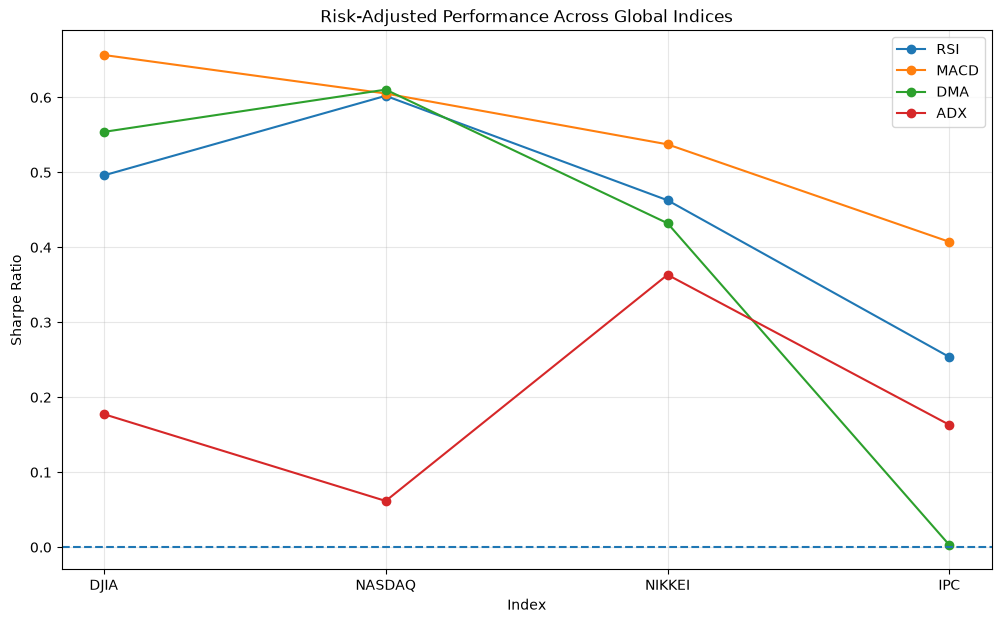

In [16]:
plt.figure(figsize=(12, 7))
for strategy_name in strategies:
    subset = results_df[
        results_df["Strategy"] == strategy_name
    ]
    plt.plot(
        subset["Index"],
        subset["Sharpe Ratio"],
        marker="o",
        label=strategy_name
    )

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Risk-Adjusted Performance Across Global Indices"
)

plt.xlabel("Index")
plt.ylabel("Sharpe Ratio")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [17]:
regime_data = {}
for name, df in processed_data.items():
    regime_data[name] = classify_regime(df)
    print(
        name,
        regime_data[name]["Regime"].value_counts()
    )

DJIA Regime
Bull    1904
Bear     964
Name: count, dtype: int64
NASDAQ Regime
Bull    1978
Bear     890
Name: count, dtype: int64
NIKKEI Regime
Bull    1745
Bear    1040
Name: count, dtype: int64
IPC Regime
Bull    1581
Bear    1286
Name: count, dtype: int64


In [18]:
regime_statistics = {}
for name, df in regime_data.items():
    stats_table = (
        df.groupby("Regime")["Return"]
        .agg([
            "mean",
            "median",
            "std",
            "min",
            "max",
            "count"
        ])
    )
    regime_statistics[name] = stats_table
regime_statistics["DJIA"]

regime_statistics["DJIA"].rename(
    columns={
        "mean": "Mean Return",
        "median": "Median Return",
        "std": "Volatility",
        "min": "Minimum Return",
        "max": "Maximum Return",
        "count": "Observations"
    }
)

,Mean Return,Median Return,Volatility,Minimum Return,Maximum Return,Observations
Regime,,,,,,
Bear,0.000505,0.000540,0.014903,-0.129265,0.113650,963
Bull,0.000387,0.000663,0.008217,-0.068982,0.038503,1904


In [19]:
for name, df in regime_data.items():
    stats_table = (
        df.groupby("Regime")["Return"]
        .agg([
            "mean",
            "median",
            "std",
            "min",
            "max",
            "count"
        ])
    )

    stats_table["Annualized Volatility"] = (
        stats_table["std"] * np.sqrt(252)
    )
    regime_statistics[name] = stats_table

In [20]:
regime_statistics["DJIA"]

,mean,median,std,min,max,count,Annualized Volatility
Regime,,,,,,,
Bear,0.000505,0.000540,0.014903,-0.129265,0.113650,963,0.236580
Bull,0.000387,0.000663,0.008217,-0.068982,0.038503,1904,0.130447


In [21]:
from scipy.stats import kurtosis

tail_statistics = {}

for name, df in regime_data.items():
    bull_returns = df.loc[
        df["Regime"] == "Bull",
        "Return"
    ].dropna()

    bear_returns = df.loc[
        df["Regime"] == "Bear",
        "Return"
    ].dropna()

    tail_statistics[name] = {
        "Bull Kurtosis": kurtosis(
            bull_returns,
            fisher=True
        ),

        "Bear Kurtosis": kurtosis(
            bear_returns,
            fisher=True
        ),
        "Bull 1% Quantile": bull_returns.quantile(0.01),
        "Bear 1% Quantile": bear_returns.quantile(0.01)
    }
tail_statistics["DJIA"]

{'Bull Kurtosis': np.float64(5.586133401859454),
 'Bear Kurtosis': np.float64(15.649633506141537),
 'Bull 1% Quantile': np.float64(-0.025546119754435534),
 'Bear 1% Quantile': np.float64(-0.040082883246825365)}

In [22]:
for name, stats_dict in tail_statistics.items():

    print("\n", name)
    print(
        "Bull 1% quantile:",
        stats_dict["Bull 1% Quantile"]
    )
    print(
        "Bear 1% quantile:",
        stats_dict["Bear 1% Quantile"]
    )


 DJIA
Bull 1% quantile: -0.025546119754435534
Bear 1% quantile: -0.040082883246825365

 NASDAQ
Bull 1% quantile: -0.03268088109119215
Bear 1% quantile: -0.04683020324333707

 NIKKEI
Bull 1% quantile: -0.031036332358101566
Bear 1% quantile: -0.045078248749538495

 IPC
Bull 1% quantile: -0.021979613870989366
Bear 1% quantile: -0.02734308890152891


In [23]:
regime_summary = []
for name, df in regime_data.items():
    for regime in ["Bull", "Bear"]:
        returns = df.loc[
            df["Regime"] == regime,
            "Return"
        ].dropna()

        regime_summary.append({
            "Index": name,
            "Regime": regime,
            "Mean Return": returns.mean(),
            "Median Return": returns.median(),
            "Daily Volatility": returns.std(),
            "Annualized Volatility": (
                returns.std() * np.sqrt(252)
            ),
            "Excess Kurtosis": kurtosis(
                returns,
                fisher=True
            ),
            "1% Quantile": returns.quantile(0.01),
            "Observations": len(returns)
        })

regime_summary_df = pd.DataFrame(
    regime_summary
)
regime_summary_df

,Index,Regime,Mean Return,Median Return,Daily Volatility,Annualized Volatility,Excess Kurtosis,1% Quantile,Observations
0,DJIA,Bull,0.000387,0.000663,0.008217,0.130447,5.586133,-0.025546,1904
1,DJIA,Bear,0.000505,0.000540,0.014903,0.236580,15.649634,-0.040083,963
2,NASDAQ,Bull,0.000657,0.001178,0.010729,0.170315,2.409682,-0.032681,1978
3,NASDAQ,Bear,0.000794,0.001117,0.018341,0.291149,6.707090,-0.046830,889
4,NIKKEI,Bull,0.000396,0.000554,0.011772,0.186881,9.150015,-0.031036,1745
5,NIKKEI,Bear,0.000866,0.001163,0.015899,0.252388,5.930567,-0.045078,1039
6,IPC,Bull,0.000096,0.000046,0.009000,0.142864,1.430741,-0.021980,1581
7,IPC,Bear,0.000372,0.000355,0.011024,0.175008,3.892957,-0.027343,1285


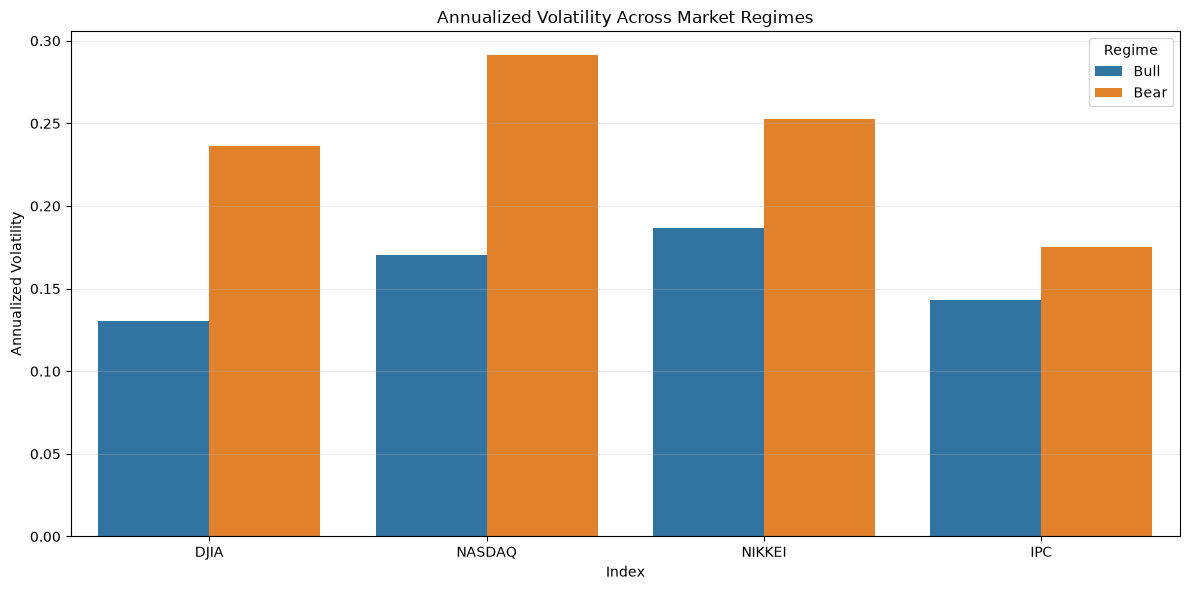

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=regime_summary_df,
    x="Index",
    y="Annualized Volatility",
    hue="Regime"
)

plt.title(
    "Annualized Volatility Across Market Regimes"
)

plt.xlabel("Index")
plt.ylabel("Annualized Volatility")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [25]:
welch_results = []

for name, df in regime_data.items():

    bull_returns = df.loc[
        df["Regime"] == "Bull",
        "Return"
    ].dropna()

    bear_returns = df.loc[
        df["Regime"] == "Bear",
        "Return"
    ].dropna()

    t_stat, p_value = stats.ttest_ind(
        bull_returns,
        bear_returns,
        equal_var=False
    )

    welch_results.append({
        "Index": name,
        "Bull Mean": bull_returns.mean(),
        "Bear Mean": bear_returns.mean(),
        "Mean Difference": (
            bull_returns.mean()
            - bear_returns.mean()
        ),
        "t-statistic": t_stat,
        "p-value": p_value
    })

welch_results_df = pd.DataFrame(
    welch_results
)

welch_results_df

welch_results_df.to_csv(
    "../results/welch_test_results.csv",
    index=False
)

In [26]:
permutation_results = []
permutation_distributions = {}
for name, df in regime_data.items():
    bull_returns = df.loc[
        df["Regime"] == "Bull",
        "Return"
    ].dropna()

    bear_returns = df.loc[
        df["Regime"] == "Bear",
        "Return"
    ].dropna()

    observed, p_value, distribution = (
        permutation_test(
            bull_returns,
            bear_returns,
            n_permutations=10000,
            seed=42
        )
    )

    permutation_results.append({
        "Index": name,
        "Observed Difference": observed,
        "Permutation p-value": p_value,
        "Iterations": 10000
    })

    permutation_distributions[name] = distribution

permutation_results_df = pd.DataFrame(
    permutation_results
)

permutation_results_df

,Index,Observed Difference,Permutation p-value,Iterations
0,DJIA,-0.000118,0.7874,10000
1,NASDAQ,-0.000137,0.8047,10000
2,NIKKEI,-0.000470,0.3764,10000
3,IPC,-0.000276,0.4696,10000


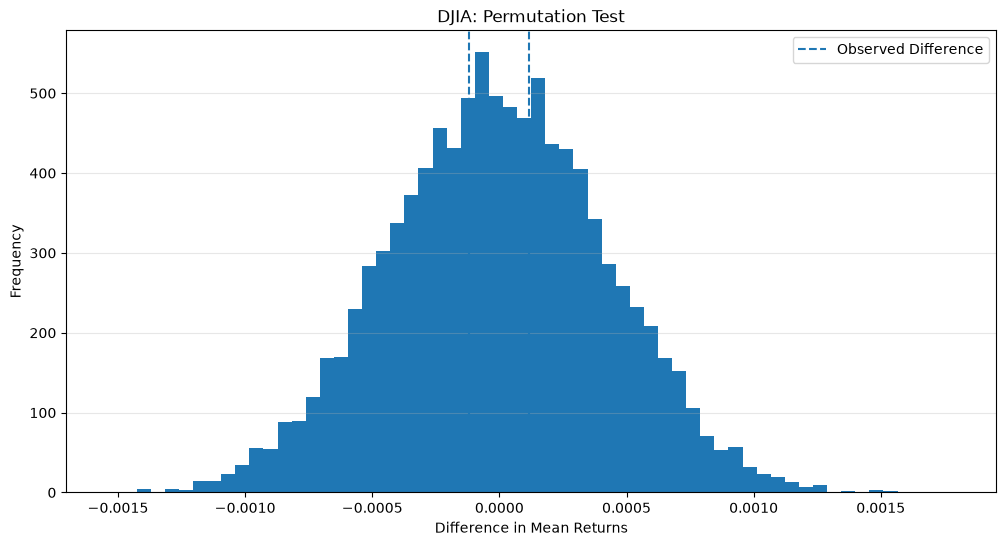

In [27]:
observed = permutation_results_df.loc[
    permutation_results_df["Index"] == "DJIA",
    "Observed Difference"
].iloc[0]

distribution = permutation_distributions["DJIA"]

plt.figure(figsize=(12, 6))

plt.hist(
    distribution,
    bins=60
)

plt.axvline(
    observed,
    linestyle="--",
    label="Observed Difference"
)

plt.axvline(
    -observed,
    linestyle="--"
)

plt.title(
    "DJIA: Permutation Test"
)

plt.xlabel(
    "Difference in Mean Returns"
)

plt.ylabel(
    "Frequency"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

permutation_results_df.to_csv(
    "../results/permutation_test_results.csv",
    index=False
)

In [28]:
dip_results = []

for name, df in regime_data.items():
    returns = df["Return"].dropna().values
    dip_statistic, p_value = (
        diptest.diptest(returns)
    )
    dip_results.append({
        "Index": name,
        "Dip Statistic": dip_statistic,
        "p-value": p_value
    })

dip_results_df = pd.DataFrame(
    dip_results
)
dip_results_df

dip_results_df.to_csv(
    "../results/dip_test_results.csv",
    index=False
)

In [29]:
statistical_summary = (
    welch_results_df
    .merge(
        permutation_results_df,
        on="Index"
    )
    .merge(
        dip_results_df,
        on="Index"
    )
)
statistical_summary

statistical_summary.to_csv(
    "../results/statistical_summary.csv",
    index=False
)

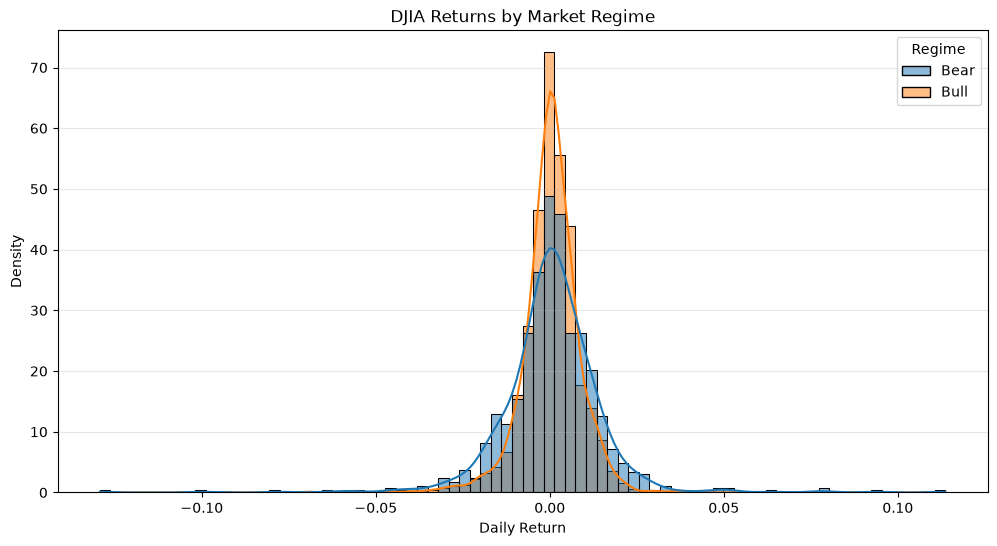

In [30]:
djia = regime_data["DJIA"]
plt.figure(figsize=(12, 6))
sns.histplot(
    data=djia,
    x="Return",
    hue="Regime",
    bins=80,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title(
    "DJIA Returns by Market Regime"
)

plt.xlabel("Daily Return")
plt.ylabel("Density")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [31]:
volatility_comparison = []

for name, df in regime_data.items():

    bull_vol = df.loc[
        df["Regime"] == "Bull",
        "Return"
    ].std()

    bear_vol = df.loc[
        df["Regime"] == "Bear",
        "Return"
    ].std()

    volatility_comparison.append({
        "Index": name,
        "Bull Volatility": bull_vol,
        "Bear Volatility": bear_vol,
        "Bear/Bull Volatility Ratio": (
            bear_vol / bull_vol
        )
    })

volatility_comparison_df = pd.DataFrame(
    volatility_comparison
)

volatility_comparison_df

,Index,Bull Volatility,Bear Volatility,Bear/Bull Volatility Ratio
0,DJIA,0.008217,0.014903,1.813612
1,NASDAQ,0.010729,0.018341,1.709474
2,NIKKEI,0.011772,0.015899,1.350526
3,IPC,0.009000,0.011024,1.224998


In [32]:
volatility_comparison_df[
    "Bear/Bull Volatility Ratio"
].mean()

np.float64(1.5246525844050116)

In [33]:
volatility_comparison_df.to_csv(
    "../results/volatility_regime_comparison.csv",
    index=False
)

In [34]:
display(results_df)
display(regime_summary_df)
display(welch_results_df)
display(permutation_results_df)
display(dip_results_df)
display(volatility_comparison_df)

,Index,Strategy,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Win Rate
0,DJIA,RSI,1.002342,0.062929,0.144050,0.495972,-0.313719,0.223927
1,DJIA,MACD,0.970283,0.061422,0.098132,0.656556,-0.150110,0.273805
2,DJIA,DMA,0.843194,0.055220,0.107508,0.553976,-0.187763,0.360656
3,DJIA,ADX,0.096409,0.008123,0.053778,0.177427,-0.157159,0.097663
4,NASDAQ,RSI,1.672948,0.090263,0.166607,0.602087,-0.271795,0.199163
5,NASDAQ,MACD,1.199042,0.071720,0.128030,0.605183,-0.246063,0.288455
6,NASDAQ,DMA,1.405759,0.080217,0.143351,0.610356,-0.331184,0.388559
7,NASDAQ,ADX,0.017010,0.001484,0.089384,0.061624,-0.299913,0.119637
8,NIKKEI,RSI,1.000639,0.064783,0.165186,0.462778,-0.273056,0.242098
9,NIKKEI,MACD,0.942828,0.061960,0.126861,0.537365,-0.176353,0.272270


,Index,Regime,Mean Return,Median Return,Daily Volatility,Annualized Volatility,Excess Kurtosis,1% Quantile,Observations
0,DJIA,Bull,0.000387,0.000663,0.008217,0.130447,5.586133,-0.025546,1904
1,DJIA,Bear,0.000505,0.000540,0.014903,0.236580,15.649634,-0.040083,963
2,NASDAQ,Bull,0.000657,0.001178,0.010729,0.170315,2.409682,-0.032681,1978
3,NASDAQ,Bear,0.000794,0.001117,0.018341,0.291149,6.707090,-0.046830,889
4,NIKKEI,Bull,0.000396,0.000554,0.011772,0.186881,9.150015,-0.031036,1745
5,NIKKEI,Bear,0.000866,0.001163,0.015899,0.252388,5.930567,-0.045078,1039
6,IPC,Bull,0.000096,0.000046,0.009000,0.142864,1.430741,-0.021980,1581
7,IPC,Bear,0.000372,0.000355,0.011024,0.175008,3.892957,-0.027343,1285


,Index,Bull Mean,Bear Mean,Mean Difference,t-statistic,p-value
0,DJIA,0.000387,0.000505,-0.000118,-0.227923,0.819743
1,NASDAQ,0.000657,0.000794,-0.000137,-0.207432,0.835709
2,NIKKEI,0.000396,0.000866,-0.000470,-0.828037,0.407765
3,IPC,0.000096,0.000372,-0.000276,-0.721632,0.470589


,Index,Observed Difference,Permutation p-value,Iterations
0,DJIA,-0.000118,0.7874,10000
1,NASDAQ,-0.000137,0.8047,10000
2,NIKKEI,-0.000470,0.3764,10000
3,IPC,-0.000276,0.4696,10000


,Index,Dip Statistic,p-value
0,DJIA,0.003670,0.996757
1,NASDAQ,0.003281,0.999808
2,NIKKEI,0.003514,0.998385
3,IPC,0.004886,0.967078


,Index,Bull Volatility,Bear Volatility,Bear/Bull Volatility Ratio
0,DJIA,0.008217,0.014903,1.813612
1,NASDAQ,0.010729,0.018341,1.709474
2,NIKKEI,0.011772,0.015899,1.350526
3,IPC,0.009000,0.011024,1.224998
